# Metal / non-metal classification with quantum kernels: bandwidth, concentration and hardware noise

IQ Hackathon 2026, QML track, Champion category. Lakshikka Sithamparanathan, Cleveland State University.

The full write-up is in `README.md`. Run the notebook top to bottom: `FAST = True` for a quick check (about 5 min), `FAST = False` for the full study (about 1 h).

In [1]:
# Install everything this notebook needs (Colab / fresh environment)
%pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" qiskit-aer qiskit-ibm-runtime scikit-learn pandas matplotlib pylatexenc mendeleev

Note: you may need to restart the kernel to use updated packages.


## 0. Configuration

Experiment sizes are set here. Hardware jobs run only when `RUN_HARDWARE = True`; finished jobs are cached in `results/` and never resubmitted.

In [2]:
import os, time, json, warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FAST = False             # True: tiny grids for a smoke test. False: full study.
RUN_HARDWARE = False     # True: submit kernel circuits to IBM hardware (needs credentials). Each job runs ONCE:
                         # results are cached in results/hw_*.npz and a submitted job is resumed, never resubmitted.
HW_BACKEND = "ibm_kingston"   # Heron r2; any of ibm_kingston / ibm_fez / ibm_marrakesh
try:                          # instance CRN from the Colab secret IBM_INSTANCE (API key: secret IBM_QUANTUM_TOKEN)
    from google.colab import userdata
    IBM_INSTANCE = userdata.get("IBM_INSTANCE")
except Exception:
    IBM_INSTANCE = os.environ.get("IBM_INSTANCE")   # outside Colab: environment variable, or None
HW_EXTRA_MAPS = ["Z", "HEA"]  # Section 9.4: also run these circuits on hardware (ZZ-full at λ* is already run in Section 8)
RUN_NOISY_SIM = True     # noisy simulation with the fake noise model of HW_BACKEND (fallback / comparison)

DATASET = "elements"        # "elements" (challenge) | "breast_cancer" | "adhoc"
INCLUDE_METALLOIDS = False  # metalloids are held out and examined separately (§8)
SEED = 42
TEST_FRAC = 0.3                                     # elements: stratified 70/30 split
N_TRAIN, N_TEST = (40, 20) if FAST else (80, 40)    # used only by the other datasets
SEEDS = list(range(3)) if FAST else list(range(10)) # independent train/test splits (small data -> many splits)
QUBITS = [2, 4, 6] if FAST else [2, 4, 6, 8, 10]
# log grid 1e-3 ... 3 (λ = 0 is the trivial all-ones kernel; above ~π the angles wrap around)
LAMBDAS = np.unique(np.r_[np.logspace(-3, np.log10(3), 7 if FAST else 15), 1.0])   # always include the default λ = 1
LAM_2D = np.logspace(-3, np.log10(3), 4 if FAST else 9)     # grid for separate (λ1, λ2)
N_2D = 4 if FAST else 6                              # qubits for the 2-D bandwidth map
SHOTS_LIST = [32, 128, 512, 2048, 8192]
SELECT_SHOTS = 1000          # realistic shot budget used for "hardware-aware" λ selection
FM_FAMILIES = ["Z", "ZZ-linear", "ZZ-full", "Pauli Y+ZZ", "HEA"]
FM_QUBITS = [4] if FAST else [4, 8]
REPS = 2

os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GRAY, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#7b4fd6"

import qiskit, qiskit_machine_learning, sklearn
print(f"qiskit {qiskit.__version__} | qiskit-ml {qiskit_machine_learning.__version__} | sklearn {sklearn.__version__}")

qiskit 2.5.2 | qiskit-ml 0.9.1 | sklearn 1.9.1


## 1. Data

Elements Z = 1–86 from the `mendeleev` database (`data/elements.csv`, rebuilt if missing). Ten features: electronegativity, first ionization energy, electron affinity, atomic, covalent and van der Waals radius, density, atomic weight, period and group.

Labels: metal = alkali, alkaline-earth, transition and post-transition metals and lanthanides (61 elements); non-metal = non-metals, halogens and noble gases (18). The 7 metalloids (B, Si, Ge, As, Sb, Te, Po) are kept aside for Section 10.

The classes are imbalanced, so all scores are balanced accuracy (0.5 = guessing) and every SVM uses `class_weight="balanced"`.

Preprocessing is fit on the training split only: median imputation, standardisation, PCA to $n$ components ($n$ = number of qubits) and rescaling to $[0, \pi]$.

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer

METAL_SERIES = {"Alkali metals", "Alkaline earth metals", "Transition metals", "Poor metals", "Lanthanides"}
NONMETAL_SERIES = {"Nonmetals", "Halogens", "Noble gases"}
FEATURES = ["electronegativity", "ionization_energy", "electron_affinity", "atomic_radius", "covalent_radius",
            "vdw_radius", "density", "atomic_weight", "period", "group"]

def build_element_table():
    # rebuild data/elements.csv from the mendeleev database (only needed if the CSV is missing)
    from mendeleev.fetch import fetch_table
    from mendeleev import element
    t = fetch_table("elements"); t = t[t.atomic_number <= 86].copy()
    t["ionization_energy"] = [element(int(z)).ionenergies.get(1, np.nan) for z in t.atomic_number]
    t["series"] = t.series_id.map(fetch_table("series").set_index("id").name)
    t = t.rename(columns={"atomic_number": "Z", "en_pauling": "electronegativity",
                          "covalent_radius_pyykko": "covalent_radius", "group_id": "group"})
    return t[["Z", "symbol", "name", "series"] + FEATURES]

def element_table():
    path = "data/elements.csv"
    if os.path.exists(path):
        t = pd.read_csv(path)
    else:
        t = build_element_table(); os.makedirs("data", exist_ok=True); t.to_csv(path, index=False)
    t["label"] = np.where(t.series.isin(METAL_SERIES), 1, np.where(t.series.isin(NONMETAL_SERIES), 0, -1))
    return t

ELEM = element_table()
print(ELEM.groupby("series").size().to_string())

def _raw(name):
    if name == "elements":
        d = ELEM if INCLUDE_METALLOIDS else ELEM[ELEM.label >= 0]
        y = d.label.clip(lower=0).values if INCLUDE_METALLOIDS else d.label.values   # metalloids -> non-metal if included
        return d[FEATURES].values.astype(float), y
    if name == "breast_cancer":
        d = load_breast_cancer()
        return d.data, d.target
    raise ValueError(name)

def load_data(n_features, seed=0):
    if DATASET == "adhoc":   # only n = 2 or 3 is supported by ad_hoc_data
        from qiskit_machine_learning.datasets import ad_hoc_data
        from qiskit_machine_learning.utils import algorithm_globals
        algorithm_globals.random_seed = 12345 + seed
        Xtr, ytr, Xte, yte = ad_hoc_data(training_size=N_TRAIN // 2, test_size=N_TEST // 2,
                                         n=n_features, gap=0.3, one_hot=False)
        return Xtr, Xte, ytr, yte
    X, y = _raw(DATASET)
    if DATASET == "elements":
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_FRAC, stratify=y, random_state=seed)
    else:
        Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=N_TRAIN, test_size=N_TEST,
                                              stratify=y, random_state=seed)
    f = fit_preprocess(Xtr, n_features, seed)
    return f(Xtr), f(Xte), ytr, yte

def fit_preprocess(Xtr, n_features, seed=0):
    # fit on the training split only (no test leakage); returns a transform for any data
    imp = SimpleImputer(strategy="median").fit(Xtr)
    std = StandardScaler().fit(imp.transform(Xtr))
    pca = PCA(n_components=n_features, random_state=seed).fit(std.transform(imp.transform(Xtr)))
    Z = pca.transform(std.transform(imp.transform(Xtr)))
    mm = MinMaxScaler((0, np.pi)).fit(Z)
    return lambda A: np.clip(mm.transform(pca.transform(std.transform(imp.transform(A)))), 0, np.pi)

Xtr, Xte, ytr, yte = load_data(4)
print(Xtr.shape, Xte.shape, "class balance (train):", np.bincount(ytr))

series
Alkali metals             5
Alkaline earth metals     5
Halogens                  5
Lanthanides              14
Metalloids                7
Noble gases               6
Nonmetals                 7
Poor metals               7
Transition metals        30
(55, 4) (24, 4) class balance (train): [13 42]


## 2. Kernels

Prototype: `zz_feature_map(n, reps=2)` with Qiskit's default data map.

Bandwidth kernel (training notebook, Part 5): two-qubit angle $x_i x_j$ and data scaled by λ. This scales the one-qubit angles by λ and the two-qubit angles by λ², so the two scales are kept separate here:

$$\varphi_i = \lambda_1 x_i, \qquad \varphi_{ij} = \lambda_2\, x_i x_j .$$

Part 5 corresponds to $\lambda_2 = \lambda_1^2$. Kernels are computed exactly from statevectors, $K_{ij} = |\langle\psi(x_i)|\psi(x_j)\rangle|^2$, and checked against Qiskit ML.

In [4]:
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector

def feature_map(n, lam1=None, lam2=None, reps=REPS):
    """lam1/lam2 = None -> prototype (Qiskit default data map)."""
    if lam1 is None:
        return zz_feature_map(n, reps=reps)
    dm = lambda x: lam1 * x[0] if len(x) == 1 else lam2 * x[0] * x[1]
    return zz_feature_map(n, reps=reps, data_map_func=dm)

def states(fm, X):
    return np.array([Statevector(fm.assign_parameters(x)).data for x in X])

def kernel(fm, XA, XB=None):
    SA = states(fm, XA)
    SB = SA if XB is None else states(fm, XB)
    return np.abs(SA.conj() @ SB.T) ** 2

def lecture_fm(n, lam):   # Part-5 convention: one-qubit λ, two-qubit λ²
    return feature_map(n, lam, lam ** 2)

# sanity check against Qiskit ML's kernel class
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
fm_chk = lecture_fm(3, 0.5)
K_ours = kernel(fm_chk, Xtr[:6, :3])
K_qml = FidelityStatevectorKernel(feature_map=fm_chk).evaluate(Xtr[:6, :3])
print("max |ours - qiskit-ml| =", np.abs(K_ours - K_qml).max())

max |ours - qiskit-ml| = 2.220446049250313e-15


## 3. Metrics

Kernel statistics (off-diagonal mean and variance, effective rank, kernel-target alignment), SVM training with C chosen by 5-fold CV, finite-shot kernel estimates and the two baselines (majority class, tuned RBF SVM).

In [5]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import balanced_accuracy_score
C_GRID = {"C": [0.1, 1, 10, 100]}
SCORING = "balanced_accuracy"     # classes are imbalanced (77 % metals)

def offdiag(K):
    return K[~np.eye(len(K), dtype=bool)]

def eff_rank(K):
    """exp(spectral entropy): ~1 for a constant kernel, ~N for the identity (memorising) kernel."""
    ev = np.clip(np.linalg.eigvalsh(K), 0, None); p = ev / ev.sum()
    p = p[p > 0]
    return float(np.exp(-(p * np.log(p)).sum()))

def kta(K, y):
    """kernel-target alignment, labels mapped to ±1"""
    s = 2 * np.asarray(y) - 1; Y = np.outer(s, s)
    return float((K * Y).sum() / (np.linalg.norm(K) * np.linalg.norm(Y)))

def fit_eval(Ktr, Kte, ytr, yte):
    """SVM with precomputed kernel; C chosen by 5-fold CV on the training set only."""
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    g = GridSearchCV(SVC(kernel="precomputed", class_weight="balanced"), C_GRID, cv=cv, scoring=SCORING).fit(Ktr, ytr)
    return dict(cv_acc=g.best_score_, test_acc=balanced_accuracy_score(yte, g.predict(Kte)), C=g.best_params_["C"])

def kernel_stats(Ktr, ytr):
    od = offdiag(Ktr)
    er = eff_rank(Ktr)
    return dict(k_mean=od.mean(), k_var=od.var(), eff_rank=er, eff_rank_frac=er / len(Ktr), kta=kta(Ktr, ytr))

def shot_kernel(K, shots, rng, symmetric=True):
    # each fidelity-kernel entry is P(0...0): finite-shot estimate = Binomial(shots, K) / shots
    Kh = rng.binomial(shots, np.clip(K, 0, 1)) / shots
    if symmetric:
        Kh = np.triu(Kh, 1); Kh = Kh + Kh.T; np.fill_diagonal(Kh, 1.0)
    return Kh

def majority_acc(ytr, yte):
    # balanced accuracy of always predicting the training majority class (= 0.5)
    return float(balanced_accuracy_score(yte, np.full_like(yte, np.bincount(ytr).argmax())))

def rbf_baseline(Xtr, Xte, ytr, yte):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    g = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"C": C_GRID["C"], "gamma": [0.01, 0.1, 1, 10, "scale"]},
                     cv=cv, scoring=SCORING)
    g.fit(Xtr, ytr)
    return balanced_accuracy_score(yte, g.predict(Xte))

## 4. Bandwidth sweep

For every qubit count, split and λ (Part 5 convention): kernel statistics, CV accuracy and test accuracy, together with the prototype, the RBF baseline and the majority-class rate. λ* is always selected by CV accuracy, never by test accuracy.

λ* is selected in two ways: from exact kernels (what a simulator sees) and from kernels estimated with `SELECT_SHOTS` shots per entry (what the hardware sees).

In [6]:
rows, t0 = [], time.time()
for seed in SEEDS:
    for n in QUBITS:
        Xtr, Xte, ytr, yte = load_data(n, seed)
        # prototype
        fm = feature_map(n)
        Ktr, Kte = kernel(fm, Xtr), kernel(fm, Xte, Xtr)
        rows.append(dict(seed=seed, n=n, model="prototype", lam=np.nan,
                         **kernel_stats(Ktr, ytr), **fit_eval(Ktr, Kte, ytr, yte)))
        # classical
        rows.append(dict(seed=seed, n=n, model="rbf", lam=np.nan, test_acc=rbf_baseline(Xtr, Xte, ytr, yte)))
        rows.append(dict(seed=seed, n=n, model="majority", lam=np.nan, test_acc=majority_acc(ytr, yte)))
        # bandwidth sweep
        for lam in LAMBDAS:
            fm = lecture_fm(n, lam)
            Ktr, Kte = kernel(fm, Xtr), kernel(fm, Xte, Xtr)
            rng_a = np.random.default_rng(7919 * seed + n)
            res_s = fit_eval(shot_kernel(Ktr, SELECT_SHOTS, rng_a), shot_kernel(Kte, SELECT_SHOTS, rng_a, False), ytr, yte)
            rows.append(dict(seed=seed, n=n, model="bandwidth", lam=lam,
                             **kernel_stats(Ktr, ytr), **fit_eval(Ktr, Kte, ytr, yte),
                             cv_acc_shots=res_s["cv_acc"], test_acc_shots=res_s["test_acc"]))
    print(f"seed {seed} done, {time.time() - t0:.0f} s")
dfA = pd.DataFrame(rows)
dfA.to_csv("results/expA_sweep.csv", index=False)

# λ* per (seed, n), selected by CV
bw = dfA[dfA.model == "bandwidth"]
best = bw.loc[bw.groupby(["seed", "n"]).cv_acc.idxmax()]
lam_star = best.groupby("n").lam.median()
best_s = bw.loc[bw.groupby(["seed", "n"]).cv_acc_shots.idxmax()]
lam_star_shots = best_s.groupby("n").lam.median()
print("λ* exact      (median over splits) per n:", lam_star.round(4).to_dict())
print(f"λ* {SELECT_SHOTS} shots (median over splits) per n:", lam_star_shots.round(4).to_dict())

seed 0 done, 90 s


seed 1 done, 180 s


seed 2 done, 273 s


seed 3 done, 362 s


seed 4 done, 450 s


seed 5 done, 537 s


seed 6 done, 624 s


seed 7 done, 710 s


seed 8 done, 799 s


seed 9 done, 887 s
λ* exact      (median over splits) per n: {2: 0.0759, 4: 0.1345, 6: 0.064, 8: 0.064, 10: 0.064}
λ* 1000 shots (median over splits) per n: {2: 0.1719, 4: 0.1719, 6: 0.097, 8: 0.097, 10: 0.097}


### Summary table

Balanced test accuracy, mean and standard deviation over the splits.

In [7]:
def summary_table(dfA):
    bw = dfA[dfA.model == "bandwidth"]
    best = bw.loc[bw.groupby(["seed", "n"]).cv_acc.idxmax()]
    best_s = bw.loc[bw.groupby(["seed", "n"]).cv_acc_shots.idxmax()]
    lam1 = bw[np.isclose(bw.lam, 1.0)].assign(model="λ = 1 (untuned)")
    parts = [dfA[dfA.model == "majority"].assign(model="majority class"),
             dfA[dfA.model == "prototype"].assign(model="prototype ZZ"), lam1,
             best.assign(model="λ* exact (simulator)"),
             best.assign(model=f"λ* exact, run at {SELECT_SHOTS} shots", test_acc=best.test_acc_shots),
             best_s.assign(model=f"λ* chosen at {SELECT_SHOTS} shots", test_acc=best_s.test_acc_shots),
             dfA[dfA.model == "rbf"].assign(model="classical RBF (tuned)")]
    t = pd.concat(parts).groupby(["n", "model"], sort=False).test_acc.agg(["mean", "std"]).unstack("model")
    return t
tab = summary_table(dfA)
tab.to_csv("results/summary_table.csv")
tab.round(3)

mean                                                    \
model majority class prototype ZZ λ = 1 (untuned) λ* exact (simulator)   
n                                                                        
2                0.5        0.597           0.605                0.896   
4                0.5        0.520           0.554                0.885   
6                0.5        0.500           0.500                0.972   
8                0.5        0.500           0.500                0.841   
10               0.5        0.500           0.500                0.830   

                                                           \
model λ* exact, run at 1000 shots λ* chosen at 1000 shots   
n                                                           
2                           0.798                   0.892   
4                           0.801                   0.867   
6                           0.836                   0.922   
8                           0.787                   0.887   
10                          0.632                   0.729   

                                       std                               \
model classical RBF (tuned) majority class prototype ZZ λ = 1 (untuned)   
n                                                                         
2                     0.893            0.0        0.125           0.163   
4                     0.972            0.0        0.063           0.105   
6                     0.975            0.0        0.000           0.000   
8                     0.895            0.0        0.000           0.000   
10                    0.871            0.0        0.000           0.000   

                                                        \
model λ* exact (simulator) λ* exact, run at 1000 shots   
n                                                        
2                    0.128                       0.214   
4                    0.205                       0.216   
6                    0.040                       0.216   
8                    0.212                       0.224   
10                   0.236                       0.213   

                                                     
model λ* chosen at 1000 shots classical RBF (tuned)  
n                                                    
2                       0.133                 0.117  
4                       0.199                 0.048  
6                       0.153                 0.041  
8                       0.171                 0.171  
10                      0.243                 0.208

## 5. Separate one- and two-qubit bandwidths

Grid over $(\lambda_1, \lambda_2)$ at `N_2D` qubits.

In [8]:
rowsB = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = load_data(N_2D, seed)
    for l1 in LAM_2D:
        for l2 in LAM_2D:
            fm = feature_map(N_2D, l1, l2)
            Ktr, Kte = kernel(fm, Xtr), kernel(fm, Xte, Xtr)
            rowsB.append(dict(seed=seed, lam1=l1, lam2=l2, **kernel_stats(Ktr, ytr), **fit_eval(Ktr, Kte, ytr, yte)))
dfB = pd.DataFrame(rowsB); dfB.to_csv("results/expB_2d.csv", index=False)
gB = dfB.groupby(["lam1", "lam2"]).mean(numeric_only=True).reset_index()
bestB = gB.loc[gB.cv_acc.idxmax()]
print(f"best (λ1, λ2) by CV at n={N_2D}: ({bestB.lam1:.3f}, {bestB.lam2:.3f})  test acc {bestB.test_acc:.3f}")

best (λ1, λ2) by CV at n=6: (0.003, 0.020)  test acc 0.979


## 6. Shot budget

Each kernel entry is the probability of measuring $|0\dots0\rangle$, so with $S$ shots it is estimated as $\mathrm{Binomial}(S, K_{ij})/S$. Every entry is resampled at finite shots and the SVM is retrained. Comparison at the largest qubit count, λ = 1 against λ*.

In [9]:
n_c = max(QUBITS)
rowsC = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = load_data(n_c, seed)
    for label, lam in [("λ = 1", 1.0), ("λ*", float(lam_star.loc[n_c]))]:
        fm = lecture_fm(n_c, lam)
        Ktr, Kte = kernel(fm, Xtr), kernel(fm, Xte, Xtr)
        for shots in SHOTS_LIST:
            for r in range(3 if FAST else 10):
                rng_s = np.random.default_rng(1000 * seed + r)
                res = fit_eval(shot_kernel(Ktr, shots, rng_s), shot_kernel(Kte, shots, rng_s, False), ytr, yte)
                rowsC.append(dict(seed=seed, setting=label, lam=lam, shots=shots, rep=r, **res))
        rowsC.append(dict(seed=seed, setting=label, lam=lam, shots=np.inf, rep=0, **fit_eval(Ktr, Kte, ytr, yte)))
dfC = pd.DataFrame(rowsC); dfC.to_csv("results/expC_shots.csv", index=False)
dfC.groupby(["setting", "shots"]).test_acc.mean().unstack(0).round(3)

setting,λ = 1,λ*
shots,,
32.0,0.5,0.641
128.0,0.5,0.659
512.0,0.5,0.698
2048.0,0.5,0.846
8192.0,0.5,0.857
inf,0.5,0.890


## 7. Feature-map comparison

Five feature maps, each swept over the same λ grid (one-qubit angles $\lambda x$, two-qubit angles $\lambda^2 x x'$ where present):

| name | circuit | entanglement |
|---|---|---|
| Z | `z_feature_map` | none |
| ZZ-linear | `zz_feature_map`, nearest-neighbour pairs | linear |
| ZZ-full | `zz_feature_map`, all pairs | all-to-all |
| Pauli Y+ZZ | `pauli_feature_map(paulis=["Y", "ZZ"])` | all-to-all |
| HEA | [RY(λx) RZ(λx), CX ladder] × reps, then a final RY(λx) RZ(λx) layer | linear |

The HEA ends on a data layer because an x-independent entangling layer at the end cancels in $U(x')^\dagger U(x)$ and does not change the fidelity kernel.

Circuit cost is counted after decomposition to CX and single-qubit gates. Entanglement is the Meyer–Wallach measure $Q = 2\big(1 - \tfrac{1}{n}\sum_k \mathrm{Tr}\,\rho_k^2\big)$, averaged over the training states.

In [10]:
from qiskit.circuit.library import z_feature_map, pauli_feature_map
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector

def family_fm(name, n, lam, reps=REPS):
    dm = lambda x: lam * x[0] if len(x) == 1 else lam ** 2 * x[0] * x[1]
    if name == "Z":          return z_feature_map(n, reps=reps, data_map_func=dm)
    if name == "ZZ-linear":  return zz_feature_map(n, reps=reps, entanglement="linear", data_map_func=dm)
    if name == "ZZ-full":    return zz_feature_map(n, reps=reps, entanglement="full", data_map_func=dm)
    if name == "Pauli Y+ZZ": return pauli_feature_map(n, reps=reps, paulis=["Y", "ZZ"], entanglement="full", data_map_func=dm)
    if name == "HEA":
        # data layer + CX ladder per rep, then a final data layer: an x-independent entangler at the
        # very end would cancel in U(x')^dagger U(x) and be invisible to the fidelity kernel
        x = ParameterVector("x", n); qc = QuantumCircuit(n)
        def data_layer():
            for i in range(n):
                qc.ry(lam * x[i], i); qc.rz(lam * x[i], i)
        for _ in range(reps):
            data_layer()
            for i in range(n - 1):
                qc.cx(i, i + 1)
        data_layer()
        return qc
    raise ValueError(name)

def circuit_cost(name, n):
    t = transpile(family_fm(name, n, 1.0), basis_gates=["cx", "u"], optimization_level=1)
    return dict(cx=t.count_ops().get("cx", 0), depth=t.depth())

def meyer_wallach(S):
    # mean Meyer-Wallach entanglement Q over a set of statevectors S (rows)
    n = int(np.log2(S.shape[1])); qs = []
    for psi in S:
        T = psi.reshape([2] * n); pur = 0.0
        for k in range(n):
            M = np.moveaxis(T, k, 0).reshape(2, -1); rho = M @ M.conj().T
            pur += np.real(np.trace(rho @ rho))
        qs.append(2 * (1 - pur / n))
    return float(np.mean(qs))

rowsE, t0 = [], time.time()
for seed in SEEDS:
    for n in FM_QUBITS:
        Xtr, Xte, ytr, yte = load_data(n, seed)
        for name in FM_FAMILIES:
            cost = circuit_cost(name, n)
            for lam in LAMBDAS:
                fm = family_fm(name, n, lam)
                Str, Ste = states(fm, Xtr), states(fm, Xte)
                Ktr, Kte = np.abs(Str.conj() @ Str.T) ** 2, np.abs(Ste.conj() @ Str.T) ** 2
                rowsE.append(dict(seed=seed, n=n, fm=name, lam=lam, mw=meyer_wallach(Str), **cost,
                                  **kernel_stats(Ktr, ytr), **fit_eval(Ktr, Kte, ytr, yte)))
    print(f"seed {seed} done, {time.time() - t0:.0f} s")
dfE = pd.DataFrame(rowsE); dfE.to_csv("results/expE_feature_maps.csv", index=False)

def fm_table(dfE):
    out = []
    for (n, name), d in dfE.groupby(["n", "fm"], sort=False):
        best = d.loc[d.groupby("seed").cv_acc.idxmax()]
        at1 = d[np.isclose(d.lam, 1.0)]
        out.append(dict(n=n, feature_map=name, cx=int(d.cx.iloc[0]), depth=int(d.depth.iloc[0]),
                        MW_entanglement_at_1=at1.mw.mean(), K_var_at_1=at1.k_var.mean(),
                        acc_at_1=at1.test_acc.mean(), lam_star=best.lam.median(),
                        acc_tuned=best.test_acc.mean(), acc_tuned_std=best.test_acc.std()))
    return pd.DataFrame(out)
tabE = fm_table(dfE); tabE.to_csv("results/expE_table.csv", index=False)
tabE.round(4)

seed 0 done, 58 s


seed 1 done, 117 s


seed 2 done, 176 s


seed 3 done, 233 s


seed 4 done, 292 s


...

seed 6 done, 412 s


seed 7 done, 476 s


seed 8 done, 540 s


seed 9 done, 601 s


,n,feature_map,cx,depth,MW_entanglement_at_1,K_var_at_1,acc_at_1,lam_star,acc_tuned,acc_tuned_std
0,4,Z,0,4,0.0000,0.0594,0.8174,0.1719,0.9195,0.1628
1,4,ZZ-linear,12,19,0.4809,0.0141,0.5363,0.1719,0.9774,0.0416
2,4,ZZ-full,24,31,0.7683,0.0085,0.5542,0.1345,0.8847,0.2051
3,4,Pauli Y+ZZ,24,33,0.3117,0.0278,0.5463,0.0970,0.7795,0.2431
4,4,HEA,6,11,0.7929,0.0496,0.9032,0.3045,0.9695,0.0387
5,8,Z,0,4,0.0000,0.0209,0.5426,0.0640,0.9511,0.0680
6,8,ZZ-linear,28,31,0.5686,0.0030,0.5000,0.0242,0.8774,0.2082
7,8,ZZ-full,112,67,0.9599,0.0008,0.5000,0.0640,0.8405,0.2119
8,8,Pauli Y+ZZ,112,69,0.5050,0.0025,0.5000,0.0970,0.8642,0.2040
9,8,HEA,14,15,0.9007,0.0168,0.5026,0.0309,0.9589,0.0699


## 8. IBM hardware

4 qubits, 12 training and 8 test points (balanced classes), `reps = 1`. Each kernel entry uses the compute–uncompute circuit $U(x_j)^\dagger U(x_i)$ with $K_{ij} = P(0\dots0)$. One job per λ: 162 circuits × 1000 shots, with XY4 dynamical decoupling and measurement twirling. λ = 1 and the λ* selected from 1000-shot kernels.

The same circuits also run on the fake noise model of `HW_BACKEND`. With `RUN_HARDWARE = False` the cached hardware results in `results/` are loaded, so this section runs without IBM credentials.

In [11]:
from qiskit.transpiler import generate_preset_pass_manager
from IPython.display import display
from itertools import combinations

N_HW_Q, N_TR_HW, N_TE_HW, HW_SHOTS = 4, 12, 8, 1000   # 66 + 96 = 162 circuits per λ
Xa, Xb, ya, yb = load_data(N_HW_Q, 0)
def balanced(X, y, m):
    i = np.r_[np.where(y == 0)[0][:m // 2], np.where(y == 1)[0][:m // 2]]
    return X[i], y[i]
Xh, yh = balanced(Xa, ya, N_TR_HW)          # hardware training set
Xh_te, yh_te = balanced(Xb, yb, N_TE_HW)    # hardware test set
pairs_tr = list(combinations(range(N_TR_HW), 2))                       # N(N-1)/2 circuits
pairs_te = [(i, j) for i in range(N_TE_HW) for j in range(N_TR_HW)]    # test x train circuits
print(f"{len(pairs_tr) + len(pairs_te)} circuits per λ")
HW_LAMS = {"lam1": 1.0, "lamstar": float(lam_star_shots.loc[N_HW_Q]) if N_HW_Q in lam_star_shots.index else 0.3}
def cached_lam(tag, default):
    # hardware jobs run once; reuse the λ they were run at so exact and hardware kernels always match
    p = f"results/hw_{tag}.npz"
    return float(np.load(p)["lam"]) if os.path.exists(p) else default
HW_LAMS = {k: cached_lam(k, v) for k, v in HW_LAMS.items()}
print("hardware λ values:", HW_LAMS)

def kernel_circuits(lam):
    fm = feature_map(N_HW_Q, lam, lam ** 2, reps=1)
    out = []
    for XA, XB, prs in [(Xh, Xh, pairs_tr), (Xh_te, Xh, pairs_te)]:
        for i, j in prs:
            qc = fm.assign_parameters(XA[i]).compose(fm.assign_parameters(XB[j]).inverse())
            qc.measure_all(); out.append(qc)
    return out

def kernels_from_counts(count_list):
    p0 = [c.get("0" * N_HW_Q, 0) / sum(c.values()) for c in count_list]
    Ktr, Kte = np.eye(N_TR_HW), np.zeros((N_TE_HW, N_TR_HW))
    for (i, j), v in zip(pairs_tr, p0[:len(pairs_tr)]):
        Ktr[i, j] = Ktr[j, i] = v
    for (i, j), v in zip(pairs_te, p0[len(pairs_tr):]):
        Kte[i, j] = v
    return Ktr, Kte

def submit(backend, lam, tag, circuits=None):
    from qiskit_ibm_runtime import SamplerV2
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    isa = pm.run(kernel_circuits(lam) if circuits is None else circuits)
    print(f"[{tag}] 2q-gate depth (max over circuits):",
          max(c.depth(lambda g: g.operation.num_qubits == 2) for c in isa))
    sampler = SamplerV2(mode=backend)
    sampler.options.default_shots = HW_SHOTS
    if getattr(backend, "name", "").startswith("ibm_"):      # error suppression on real hardware only
        sampler.options.dynamical_decoupling.enable = True
        sampler.options.dynamical_decoupling.sequence_type = "XY4"
        sampler.options.twirling.enable_measure = True
    job = sampler.run(isa)
    print(f"[{tag}] job id:", job.job_id())
    return job

def run_on(backend, lam, tag, circuits=None):
    job = submit(backend, lam, tag, circuits)
    res = job.result()
    return kernels_from_counts([r.data.meas.get_counts() for r in res]), job.job_id()

from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import fake_provider
FAKE_BACKEND = {"ibm_kingston": "FakeKingston", "ibm_fez": "FakeFez", "ibm_marrakesh": "FakeMarrakesh"}[HW_BACKEND]
fake = AerSimulator.from_backend(getattr(fake_provider, FAKE_BACKEND)())

_service = None
def hw_backend():
    global _service
    from qiskit_ibm_runtime import QiskitRuntimeService
    if _service is None:
        token = os.environ.get("IBM_QUANTUM_TOKEN")
        try:                                   # Colab secret named IBM_QUANTUM_TOKEN
            from google.colab import userdata
            token = token or userdata.get("IBM_QUANTUM_TOKEN")
        except Exception:
            pass
        _service = (QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=IBM_INSTANCE)
                    if token else QiskitRuntimeService(instance=IBM_INSTANCE))
    return _service.backend(HW_BACKEND)

def hw_kernels(tag, lam, circuits=None):
    """Run on hardware once; cache. Returns (Ktr, Kte) or None."""
    path, jpath = f"results/hw_{tag}.npz", f"results/hw_{tag}_job.json"
    if os.path.exists(path):
        z = np.load(path); print(f"[hw {tag}] cached ({z['backend']}, job {z['job_id']})")
        return z["Ktr"], z["Kte"]
    if not RUN_HARDWARE:
        return None
    backend = hw_backend()
    if os.path.exists(jpath):                  # job already submitted earlier: resume, do not resubmit
        job = _service.job(json.load(open(jpath))["job_id"]); print(f"[hw {tag}] resuming job {job.job_id()}")
    else:
        job = submit(backend, lam, f"hw {tag}", circuits)
        json.dump(dict(job_id=job.job_id(), lam=lam, backend=backend.name), open(jpath, "w"))
    res = job.result()
    Ktr, Kte = kernels_from_counts([r.data.meas.get_counts() for r in res])
    np.savez(path, Ktr=Ktr, Kte=Kte, job_id=job.job_id(), lam=lam, backend=backend.name)
    try:
        print(f"[hw {tag}] QPU seconds used: {job.metrics()['usage']['quantum_seconds']}")
    except Exception:
        pass
    return Ktr, Kte

hw = {}
for key, lam in HW_LAMS.items():
    fm_e = feature_map(N_HW_Q, lam, lam ** 2, reps=1)
    hw[key] = dict(lam=lam, exact=kernel(fm_e, Xh), exact_test=kernel(fm_e, Xh_te, Xh))
    if RUN_NOISY_SIM:
        (hw[key]["noisy_sim"], hw[key]["noisy_sim_test"]), _ = run_on(fake, lam, f"fake {key}")
    hwK = hw_kernels(key, lam)
    if hwK is not None:
        hw[key]["hardware"], hw[key]["hardware_test"] = hwK

def small_fit_eval(Ktr, Kte, ytr, yte):
    # same procedure for every kernel source: C by stratified 4-fold CV on the 12 training points
    g = GridSearchCV(SVC(kernel="precomputed", class_weight="balanced"), {"C": [0.1, 1, 10, 100, 1000]},
                     cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring=SCORING).fit(Ktr, ytr)
    return balanced_accuracy_score(yte, g.predict(Kte)), g.best_params_["C"]

hw_rows = []
for key, d in hw.items():
    for src in [s for s in ("exact", "noisy_sim", "hardware") if s in d]:
        acc, Cb = small_fit_eval(d[src], d[src + "_test"], yh, yh_te)
        hw_rows.append(dict(lam=round(d["lam"], 4), source=src, test_acc=acc, C=Cb, kta=kta(d[src], yh),
                            k_mean=offdiag(d[src]).mean(), k_var=offdiag(d[src]).var()))
hw_tab = pd.DataFrame(hw_rows); hw_tab.to_csv("results/expD_hw_table.csv", index=False)
display(hw_tab.round(4))
for key, d in hw.items():
    for src in [s for s in ("noisy_sim", "hardware") if s in d]:
        e = offdiag(d[src]) - offdiag(d["exact"])
        print(f"{key:8s} λ={d['lam']:.3f} {src:9s}: mean shift {e.mean():+.3f}, "
              f"var exact {offdiag(d['exact']).var():.4f} -> {offdiag(d[src]).var():.4f}")

162 circuits per λ
hardware λ values: {'lam1': 1.0, 'lamstar': 0.2080083823051904}


[fake lam1] 2q-gate depth (max over circuits): 34


[fake lam1] job id: 6b6503f5-9c3c-47bb-8247-a4afdf03f8a3


[hw lam1] cached (ibm_kingston, job dbef01vpc3tc739ligc0)


[fake lamstar] 2q-gate depth (max over circuits): 34


[fake lamstar] job id: bfd86590-ecdc-4537-b196-0a2e48acf5e0


[hw lamstar] cached (ibm_kingston, job dbef10nsstms73fbuim0)


,lam,source,test_acc,C,kta,k_mean,k_var
0,1.000,exact,0.500,1,0.2913,0.0872,0.0085
1,1.000,noisy_sim,0.500,1,0.2938,0.0838,0.0071
2,1.000,hardware,0.500,10,0.2836,0.0824,0.0057
3,0.208,exact,1.000,10,0.0839,0.7683,0.0162
4,0.208,noisy_sim,0.875,1,0.0920,0.7082,0.0130
5,0.208,hardware,0.875,1,0.0951,0.6563,0.0109


lam1     λ=1.000 noisy_sim: mean shift -0.003, var exact 0.0085 -> 0.0071
lam1     λ=1.000 hardware : mean shift -0.005, var exact 0.0085 -> 0.0057
lamstar  λ=0.208 noisy_sim: mean shift -0.060, var exact 0.0162 -> 0.0130
lamstar  λ=0.208 hardware : mean shift -0.112, var exact 0.0162 -> 0.0109


## 9. Feature-map analysis

4-qubit problem, split 0.

* 9.1 Kernel matrices at λ = 1 and at each circuit's λ*, rows and columns sorted non-metals | metals.
* 9.2 Kernel-target alignment against λ, and the geometric difference $g(K^{C}\Vert K^{Q}) = \sqrt{\lVert \sqrt{K^{Q}}\,(K^{C})^{-1}\sqrt{K^{Q}}\rVert_\infty}$ to a tuned RBF kernel (Huang *et al.*, *Nat. Commun.* 12, 2631, 2021). A value of $g$ close to 1 means the classical kernel can represent the quantum one.
* 9.3 Circuit depth, `reps` = 1, 2, 3.
* 9.4 Kernel error under the noise model and, for `HW_EXTRA_MAPS`, on hardware, against the number of two-qubit gates.

In [12]:
N_G = 4
XtrG, XteG, ytrG, yteG = load_data(N_G, 0)
order = np.argsort(ytrG, kind="stable"); n0 = int((ytrG == 0).sum())
lam_map = tabE[tabE.n == N_G].set_index("feature_map").lam_star.to_dict()
print("tuned λ* per circuit (n = 4):", {k: round(v, 3) for k, v in lam_map.items()})

# 9.1 kernel matrices
G_kernels = {(name, tag): kernel(family_fm(name, N_G, lam), XtrG)
             for name in FM_FAMILIES for tag, lam in [("λ = 1", 1.0), ("λ*", lam_map[name])]}

# 9.2 alignment and geometric difference vs λ
def geometric_difference(Kq, Kc, reg=1e-3):
    w, V = np.linalg.eigh(Kq); sq = (V * np.sqrt(np.clip(w, 0, None))) @ V.T
    M = sq @ np.linalg.inv(Kc + reg * np.eye(len(Kc))) @ sq
    return float(np.sqrt(np.max(np.linalg.eigvalsh((M + M.T) / 2))))

D2 = ((XtrG[:, None, :] - XtrG[None, :, :]) ** 2).sum(-1)
gamma_c = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"C": C_GRID["C"], "gamma": [0.01, 0.1, 1, 10]},
                       cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=SCORING).fit(XtrG, ytrG).best_params_["gamma"]
Kc = np.exp(-gamma_c * D2)
rowsG2 = []
for name in FM_FAMILIES:
    for lam in LAMBDAS:
        K = kernel(family_fm(name, N_G, lam), XtrG)
        rowsG2.append(dict(fm=name, lam=lam, kta=kta(K, ytrG), g_vs_rbf=geometric_difference(K, Kc)))
dfG2 = pd.DataFrame(rowsG2); dfG2.to_csv("results/expG2_alignment_geomdiff.csv", index=False)
print(f"classical RBF γ = {gamma_c}; KTA of the RBF kernel = {kta(Kc, ytrG):.3f}")

# 9.3 depth (reps) sweep, λ tuned by CV per split
rowsG3 = []
for seed in SEEDS[:3]:
    Xtr, Xte, ytr, yte = load_data(N_G, seed)
    for name in FM_FAMILIES:
        for reps in [1, 2, 3]:
            res = []
            for lam in LAMBDAS:
                fm = family_fm(name, N_G, lam, reps=reps)
                Ktr, Kte = kernel(fm, Xtr), kernel(fm, Xte, Xtr)
                res.append(dict(lam=lam, k_var=offdiag(Ktr).var(), **fit_eval(Ktr, Kte, ytr, yte)))
            r = pd.DataFrame(res); b = r.loc[r.cv_acc.idxmax()]; one = r[np.isclose(r.lam, 1.0)].iloc[0]
            rowsG3.append(dict(seed=seed, fm=name, reps=reps, lam_star=b.lam, acc_tuned=b.test_acc,
                               acc_at_1=one.test_acc, k_var_at_1=one.k_var))
dfG3 = pd.DataFrame(rowsG3); dfG3.to_csv("results/expG3_reps.csv", index=False)
display(dfG3.groupby(["fm", "reps"], sort=False)[["acc_at_1", "acc_tuned", "k_var_at_1"]].mean().unstack("reps").round(3))

tuned λ* per circuit (n = 4): {'Z': 0.172, 'ZZ-linear': 0.172, 'ZZ-full': 0.134, 'Pauli Y+ZZ': 0.097, 'HEA': 0.305}


classical RBF γ = 0.1; KTA of the RBF kernel = 0.358


acc_at_1               acc_tuned               k_var_at_1         \
reps              1      2      3         1      2      3          1      2   
fm                                                                            
Z             0.956  0.881  0.798     0.974  1.000  1.000      0.065  0.058   
ZZ-linear     0.507  0.549  0.540     1.000  1.000  1.000      0.017  0.014   
ZZ-full       0.525  0.607  0.523     0.991  0.991  0.991      0.012  0.009   
Pauli Y+ZZ    0.949  0.635  0.632     0.991  0.982  0.991      0.025  0.030   
HEA           0.933  0.886  0.916     1.000  0.958  0.967      0.065  0.049   

                   
reps            3  
fm                 
Z           0.043  
ZZ-linear   0.015  
ZZ-full     0.008  
Pauli Y+ZZ  0.018  
HEA         0.042

In [13]:
# 9.4 noise robustness per circuit (fake noise model + optional real hardware, reps = 1, each circuit at its own λ*)
def circuits_for(fm):
    out = []
    for XA, XB, prs in [(Xh, Xh, pairs_tr), (Xh_te, Xh, pairs_te)]:
        for i, j in prs:
            qc = fm.assign_parameters(XA[i]).compose(fm.assign_parameters(XB[j]).inverse())
            qc.measure_all(); out.append(qc)
    return out

pm_fake = generate_preset_pass_manager(optimization_level=3, backend=fake)
rowsG4 = []
for name in FM_FAMILIES:
    lam = cached_lam(f"G4_{name}", lam_map[name]) if name in HW_EXTRA_MAPS else lam_map[name]
    if name == "ZZ-full":
        lam = HW_LAMS["lamstar"]          # same λ as the Section 8 hardware job
    fm = family_fm(name, N_HW_Q, lam, reps=1)
    Ktr_e, Kte_e = kernel(fm, Xh), kernel(fm, Xh_te, Xh)
    circs = circuits_for(fm)
    n2q = np.mean([c.count_ops().get("cz", 0) + c.count_ops().get("ecr", 0) + c.count_ops().get("cx", 0)
                   for c in pm_fake.run(circs[:20])])
    (Ktr_n, Kte_n), _ = run_on(fake, lam, f"fake {name}", circuits=circs)
    acc_e, _ = small_fit_eval(Ktr_e, Kte_e, yh, yh_te)
    acc_n, _ = small_fit_eval(Ktr_n, Kte_n, yh, yh_te)
    row = dict(fm=name, lam=lam, two_qubit_gates=n2q, acc_exact=acc_e, acc_noisy=acc_n,
               mean_abs_shift=np.abs(offdiag(Ktr_n) - offdiag(Ktr_e)).mean(),
               var_exact=offdiag(Ktr_e).var(), var_noisy=offdiag(Ktr_n).var())
    # real hardware: ZZ-full at λ* is the Section 8 "lamstar" job; the others run only if listed in HW_EXTRA_MAPS
    hwK = (hw["lamstar"].get("hardware"), hw["lamstar"].get("hardware_test")) \
          if (name == "ZZ-full" and np.isclose(lam, HW_LAMS["lamstar"])) else \
          (hw_kernels(f"G4_{name}", lam, circuits=circs) if name in HW_EXTRA_MAPS else None)
    if hwK is not None and hwK[0] is not None:
        row.update(acc_hw=small_fit_eval(hwK[0], hwK[1], yh, yh_te)[0],
                   mean_abs_shift_hw=np.abs(offdiag(hwK[0]) - offdiag(Ktr_e)).mean())
    rowsG4.append(row)
dfG4 = pd.DataFrame(rowsG4); dfG4.to_csv("results/expG4_noise_per_circuit.csv", index=False)
display(dfG4.round(4))

[fake Z] 2q-gate depth (max over circuits): 0


[fake Z] job id: f39b1343-bda5-4df1-a998-90af1afc2d19


[hw G4_Z] cached (ibm_kingston, job dbef3cvsstms73fbuma0)


[fake ZZ-linear] 2q-gate depth (max over circuits): 10


[fake ZZ-linear] job id: 0e8f9966-40d2-4e62-ade1-3a2878bc83e8


...

[fake Pauli Y+ZZ] job id: 4b02640a-b868-493c-aedf-34bc90e3bf6e


[fake HEA] 2q-gate depth (max over circuits): 6


[fake HEA] job id: e684a537-ea7d-4ca2-b35f-2de845ad2e2c


[hw G4_HEA] cached (ibm_kingston, job dbef4evsstms73fbunv0)


,fm,lam,two_qubit_gates,acc_exact,acc_noisy,mean_abs_shift,var_exact,var_noisy,acc_hw,mean_abs_shift_hw
0,Z,0.2080,0.00,0.875,0.875,0.0144,0.0103,0.0099,1.000,0.0196
1,ZZ-linear,0.1719,9.60,0.875,0.875,0.0367,0.0069,0.0060,NaN,NaN
2,ZZ-full,0.2080,31.00,1.000,0.750,0.0638,0.0162,0.0135,0.875,0.1121
3,Pauli Y+ZZ,0.0970,31.25,1.000,0.625,0.0772,0.0008,0.0007,NaN,NaN
4,HEA,0.2080,6.00,0.875,0.875,0.0343,0.0081,0.0076,0.875,0.0562


## 10. Metalloids

The SVM is trained on all 79 labelled elements (4 qubits, λ* and λ = 1) and evaluated on the 7 metalloids. A decision value > 0 means metal, < 0 non-metal. The cell also lists the labelled elements that are misclassified under 10-fold CV.

In [14]:
from sklearn.model_selection import cross_val_predict
N_META = 4
lam_meta = float(lam_star.loc[N_META]) if N_META in lam_star.index else 0.1
known = ELEM[ELEM.label >= 0]; metalloids = ELEM[ELEM.label == -1]
f_meta = fit_preprocess(known[FEATURES].values.astype(float), N_META)
Xk, yk, Xm = f_meta(known[FEATURES].values.astype(float)), known.label.values, f_meta(metalloids[FEATURES].values.astype(float))

def decision_values(fm):
    Kk = kernel(fm, Xk)
    g = GridSearchCV(SVC(kernel="precomputed", class_weight="balanced"), C_GRID,
                     cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=SCORING).fit(Kk, yk)
    return g.best_estimator_.decision_function(kernel(fm, Xm, Xk)), g, Kk

dec_star, g_star, K_star = decision_values(lecture_fm(N_META, lam_meta))
dec_one, _, _ = decision_values(lecture_fm(N_META, 1.0))
grbf = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"C": C_GRID["C"], "gamma": [0.01, 0.1, 1, 10, "scale"]},
                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=SCORING).fit(Xk, yk)
dfF = pd.DataFrame({"element": metalloids.symbol.values, "Z": metalloids.Z.values,
                    f"quantum λ*={lam_meta:.3g}": dec_star, "quantum λ=1": dec_one,
                    "classical RBF": grbf.best_estimator_.decision_function(Xm)})
dfF.to_csv("results/expF_metalloids.csv", index=False)
display(dfF.round(3))

# which ordinary elements does the tuned quantum model get wrong? (10-fold CV predictions)
pred = cross_val_predict(SVC(kernel="precomputed", class_weight="balanced", C=g_star.best_params_["C"]),
                         K_star, yk, cv=StratifiedKFold(10, shuffle=True, random_state=SEED))
wrong = known.assign(pred=pred)[pred != yk][["symbol", "name", "series", "label", "pred"]]
print(f"CV balanced accuracy at λ*: {balanced_accuracy_score(yk, pred):.3f}; misclassified elements:")
display(wrong)

,element,Z,quantum λ*=0.134,quantum λ=1,classical RBF
0,B,5,-0.227,0.565,-0.108
1,Si,14,-0.271,0.659,-0.274
2,Ge,32,-0.026,0.705,0.038
3,As,33,-0.216,0.694,-0.171
4,Sb,51,-0.029,0.755,-0.049
5,Te,52,-0.217,0.496,-0.431
6,Po,84,0.077,0.735,-0.174


CV balanced accuracy at λ*: 0.972; misclassified elements:


,symbol,name,series,label,pred
0,H,Hydrogen,Nonmetals,0,1


## 11. Figures

All figures are saved to `figures/`.

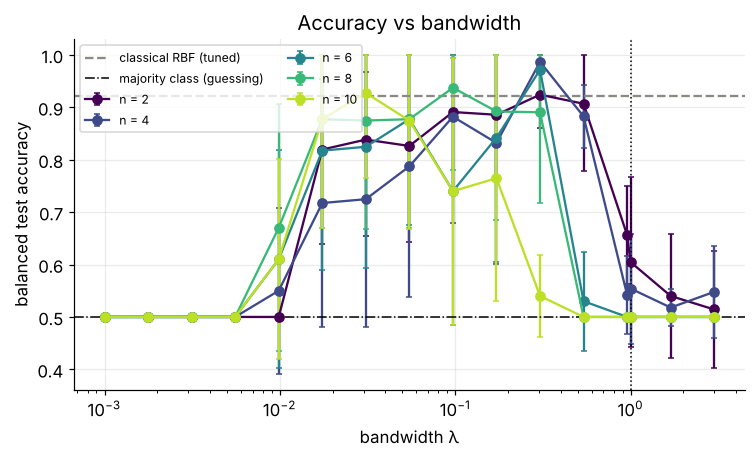

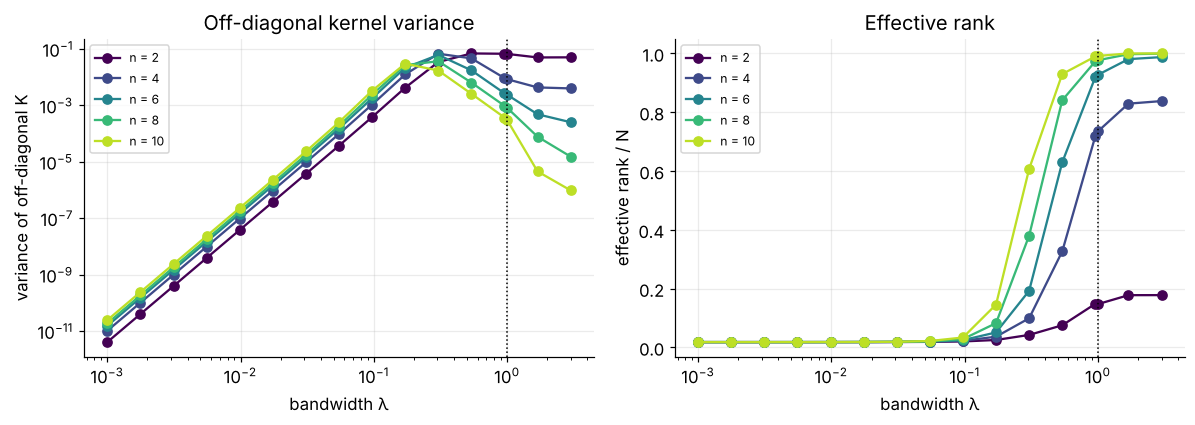

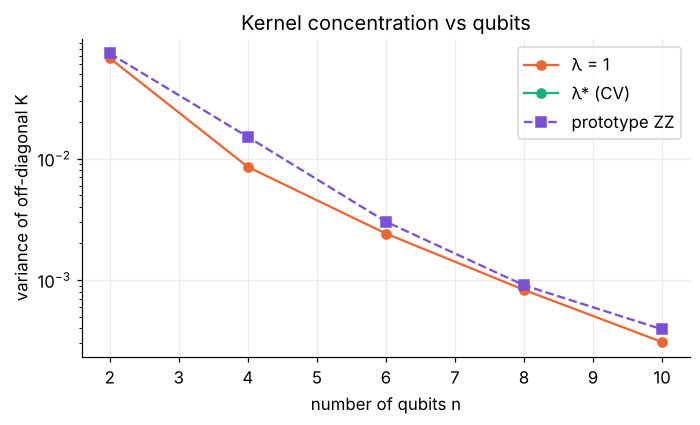

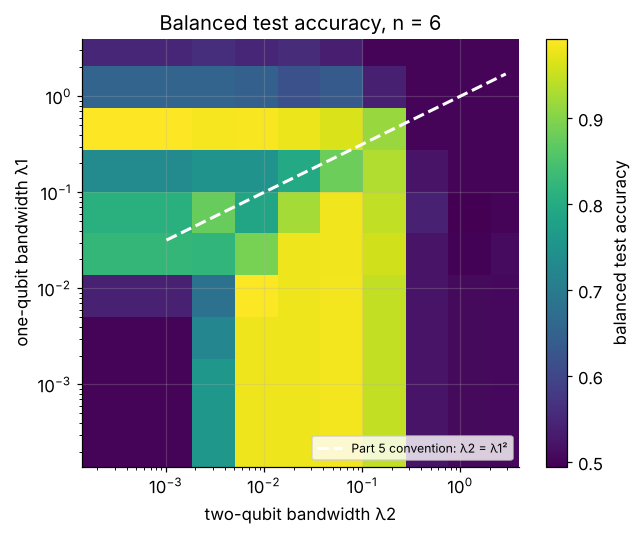

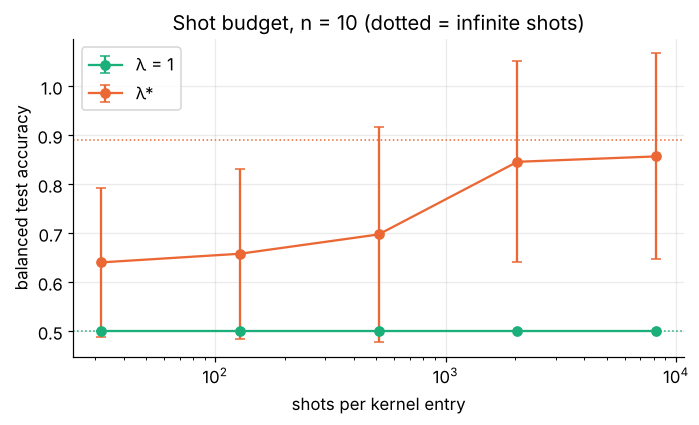

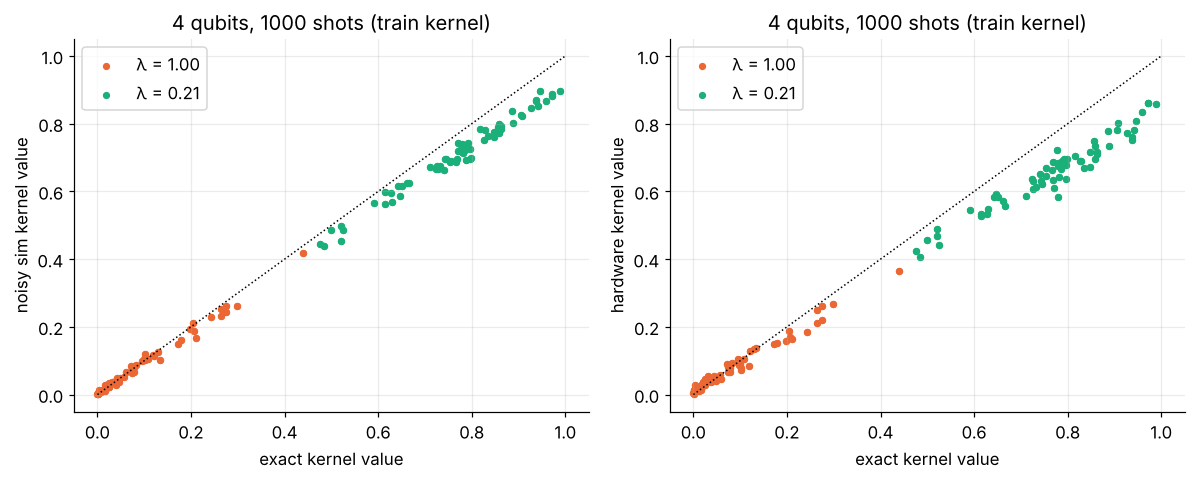

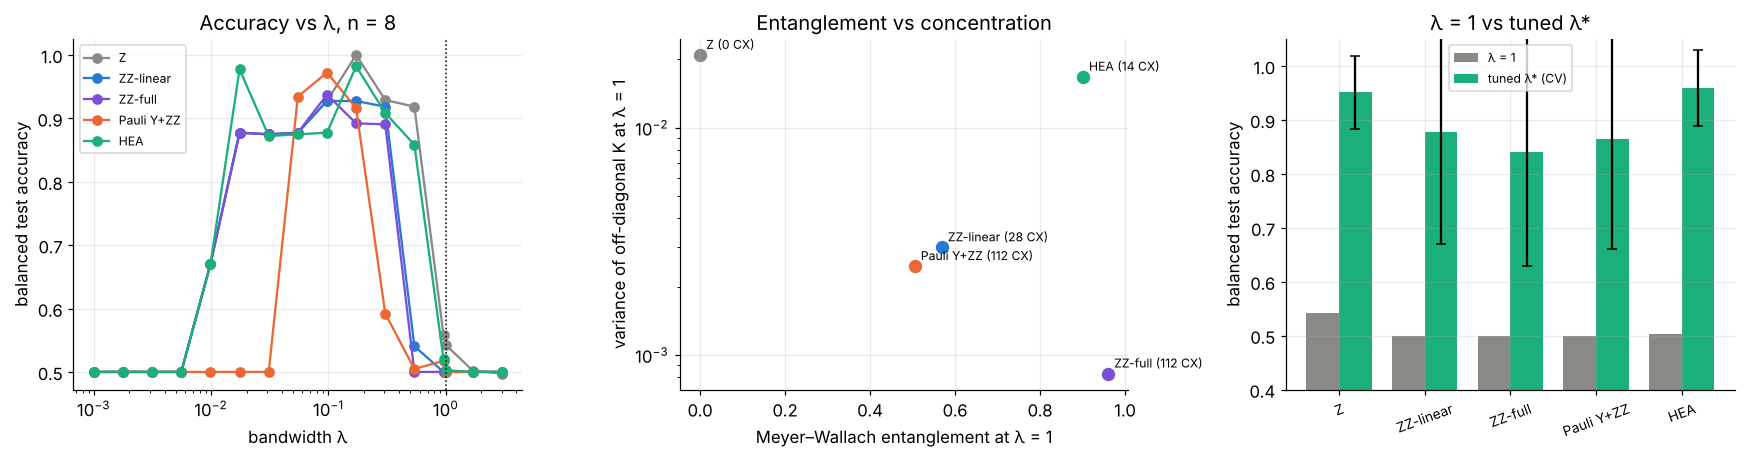

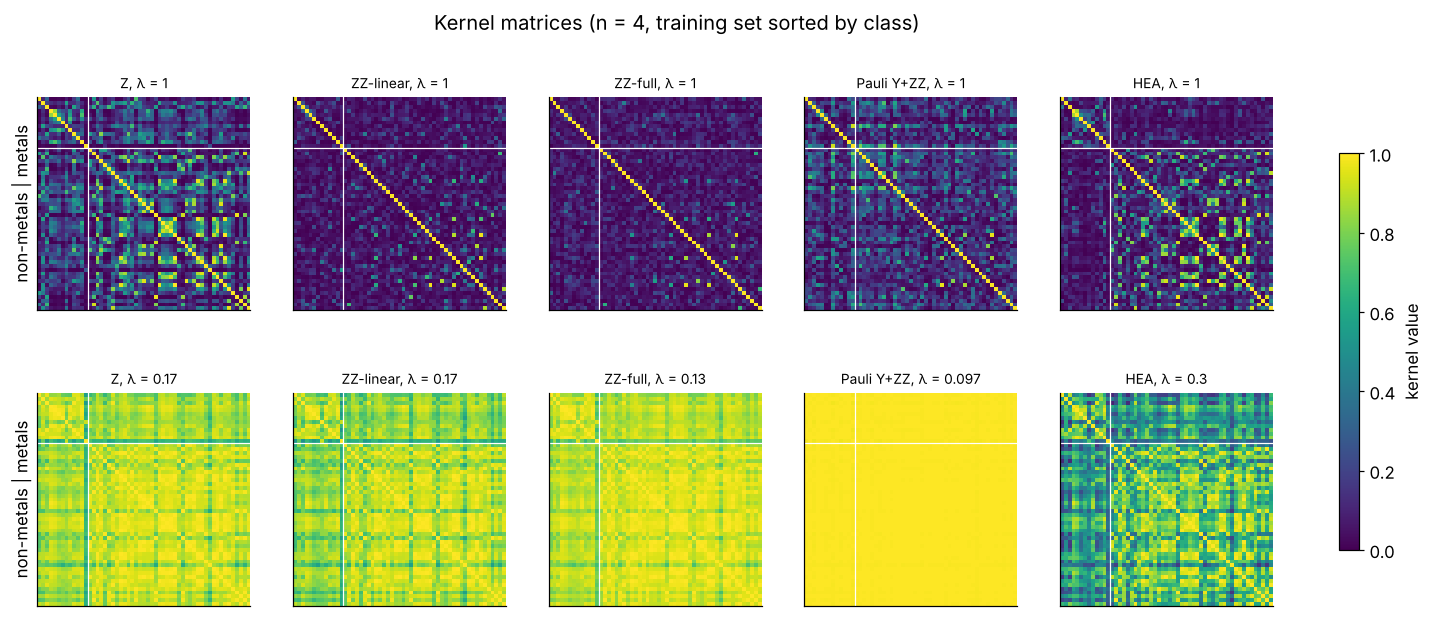

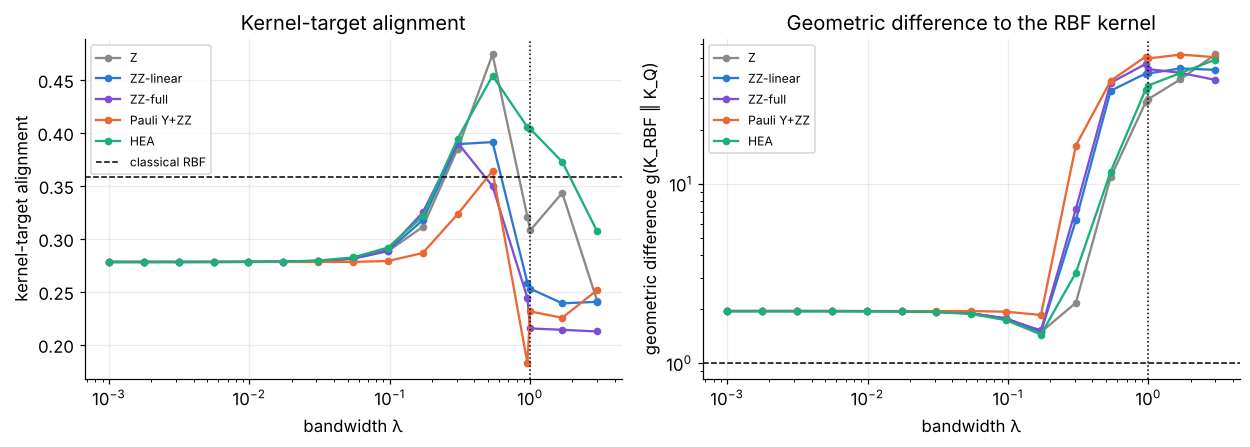

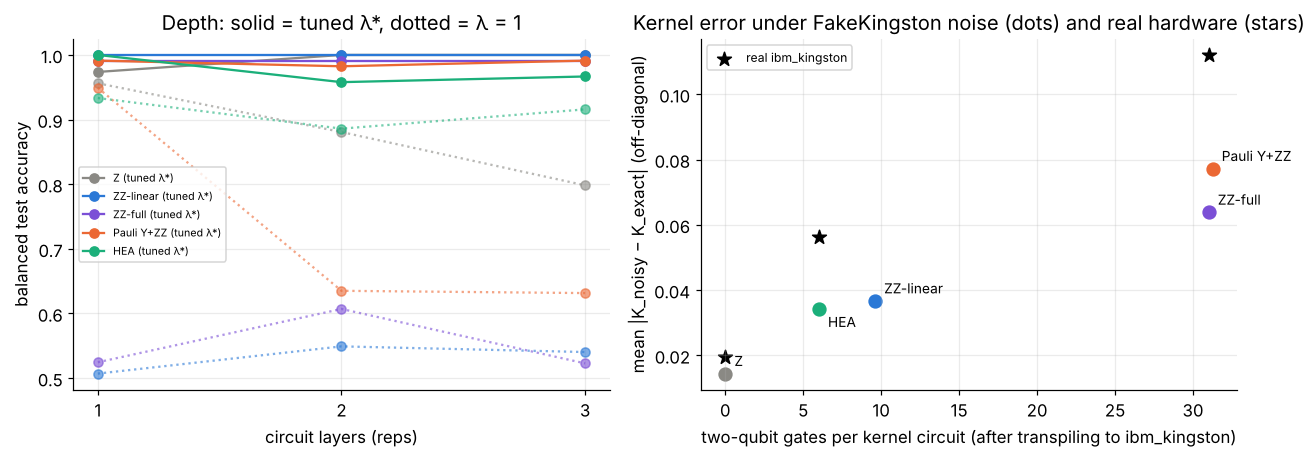

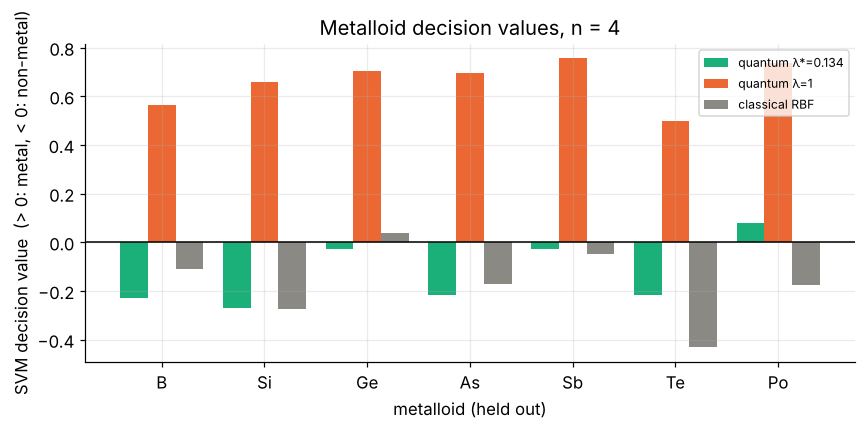

In [15]:
def fig1_accuracy_vs_lambda(dfA):
    bw = dfA[dfA.model == "bandwidth"]
    g = bw.groupby(["n", "lam"]).test_acc.agg(["mean", "std"]).reset_index()
    rbf = dfA[dfA.model == "rbf"].test_acc.mean()
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(QUBITS)))
    fig, ax = plt.subplots(figsize=(7, 4.3))
    for c, n in zip(cmap, QUBITS):
        s = g[g.n == n]
        sd = s["std"].fillna(0).values; m = s["mean"].values
        yerr = [np.minimum(sd, m - 0), np.minimum(sd, 1 - m)]        # accuracy is bounded by [0, 1]
        ax.errorbar(s.lam, m, yerr=yerr, marker="o", color=c, capsize=2, label=f"n = {n}")
    ax.axhline(rbf, ls="--", color=GRAY, label="classical RBF (tuned)")
    ax.axhline(dfA[dfA.model == "majority"].test_acc.mean(), ls="-.", color="k", lw=1, label="majority class (guessing)")
    ax.axvline(1.0, ls=":", color="k", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("bandwidth λ"); ax.set_ylabel("balanced test accuracy")
    ax.set_title("Accuracy vs bandwidth"); ax.legend(fontsize=8, ncol=2)
    fig.tight_layout(); fig.savefig("figures/fig1_accuracy_vs_lambda.png", dpi=200); plt.show()

def fig2_two_sided_failure(dfA):
    bw = dfA[dfA.model == "bandwidth"]
    g = bw.groupby(["n", "lam"])[["k_var", "eff_rank_frac"]].mean().reset_index()
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(QUBITS)))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    for c, n in zip(cmap, QUBITS):
        s = g[g.n == n]
        a1.loglog(s.lam, s.k_var, "o-", color=c, label=f"n = {n}")
        a2.semilogx(s.lam, s.eff_rank_frac, "o-", color=c, label=f"n = {n}")
    a1.set_xlabel("bandwidth λ"); a1.set_ylabel("variance of off-diagonal K")
    a1.set_title("Off-diagonal kernel variance")
    a2.set_xlabel("bandwidth λ"); a2.set_ylabel("effective rank / N")
    a2.set_title("Effective rank")
    for a in (a1, a2): a.axvline(1.0, ls=":", color="k", lw=1); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig("figures/fig2_two_sided_failure.png", dpi=200); plt.show()

def fig3_concentration_vs_n(dfA, lam_star):
    bw = dfA[dfA.model == "bandwidth"]
    v1 = bw[np.isclose(bw.lam, 1.0)].groupby("n").k_var.mean()
    vs = pd.Series({n: bw[(bw.n == n) & np.isclose(bw.lam, lam_star[n])].k_var.mean() for n in QUBITS})
    vp = dfA[dfA.model == "prototype"].groupby("n").k_var.mean()
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.semilogy(v1.index, v1.values, "o-", color=ORANGE, label="λ = 1")
    ax.semilogy(vs.index, vs.values, "o-", color=GREEN, label="λ* (CV)")
    ax.semilogy(vp.index, vp.values, "s--", color=PURPLE, label="prototype ZZ")
    ax.set_xlabel("number of qubits n"); ax.set_ylabel("variance of off-diagonal K")
    ax.set_title("Kernel concentration vs qubits"); ax.legend()
    fig.tight_layout(); fig.savefig("figures/fig3_concentration_vs_n.png", dpi=200); plt.show()

def fig4_lambda_2d(dfB):
    g = dfB.groupby(["lam1", "lam2"]).test_acc.mean().unstack("lam2")
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.pcolormesh(g.columns, g.index, g.values, cmap="viridis", shading="nearest")
    l1 = np.logspace(np.log10(LAM_2D.min()), np.log10(LAM_2D.max()), 200)
    m = (l1 ** 2 >= LAM_2D.min()) & (l1 ** 2 <= LAM_2D.max())
    ax.plot(l1[m] ** 2, l1[m], "w--", lw=2, label="Part 5 convention: λ2 = λ1²")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("two-qubit bandwidth λ2"); ax.set_ylabel("one-qubit bandwidth λ1")
    ax.set_title(f"Balanced test accuracy, n = {N_2D}"); ax.legend(fontsize=8, loc="lower right")
    fig.colorbar(im, ax=ax, label="balanced test accuracy")
    fig.tight_layout(); fig.savefig("figures/fig4_lambda_2d.png", dpi=200); plt.show()

def fig5_shots(dfC):
    fin = dfC[np.isfinite(dfC.shots)]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for (label, d), c in zip(fin.groupby("setting"), [GREEN, ORANGE]):
        g = d.groupby("shots").test_acc.agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, color=c, label=label)
        exact = dfC[(dfC.setting == label) & ~np.isfinite(dfC.shots)].test_acc.mean()
        ax.axhline(exact, ls=":", color=c, lw=1)
    ax.set_xscale("log"); ax.set_xlabel("shots per kernel entry"); ax.set_ylabel("balanced test accuracy")
    ax.set_title(f"Shot budget, n = {n_c} (dotted = infinite shots)"); ax.legend()
    fig.tight_layout(); fig.savefig("figures/fig5_shots.png", dpi=200); plt.show()

def fig6_hardware(hw):
    srcs = [s for s in ("noisy_sim", "hardware") if any(s in d for d in hw.values())]
    if not srcs:
        print("no noisy/hardware kernels available"); return
    fig, axes = plt.subplots(1, len(srcs), figsize=(5.5 * len(srcs), 4.5), squeeze=False)
    for ax, src in zip(axes[0], srcs):
        for (key, d), c in zip(hw.items(), [ORANGE, GREEN]):
            if src in d:
                ax.scatter(offdiag(d["exact"]), offdiag(d[src]), s=14, color=c, label=f"λ = {d['lam']:.2f}")
        ax.plot([0, 1], [0, 1], "k:", lw=1)
        ax.set_xlabel("exact kernel value"); ax.set_ylabel(f"{src.replace('_', ' ')} kernel value")
        ax.set_title(f"{N_HW_Q} qubits, {HW_SHOTS} shots (train kernel)"); ax.legend()
    fig.tight_layout(); fig.savefig("figures/fig6_hardware.png", dpi=200); plt.show()

def fig7_feature_maps(dfE, tabE):
    nmax = max(FM_QUBITS)
    t = tabE[tabE.n == nmax]
    cols = dict(zip(FM_FAMILIES, [GRAY, BLUE, PURPLE, ORANGE, GREEN]))
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.3))
    g = dfE[dfE.n == nmax].groupby(["fm", "lam"]).test_acc.mean().reset_index()
    for name in FM_FAMILIES:
        s = g[g.fm == name]; a1.semilogx(s.lam, s.test_acc, "o-", color=cols[name], label=name)
    a1.axvline(1.0, ls=":", color="k", lw=1)
    a1.set_xlabel("bandwidth λ"); a1.set_ylabel("balanced test accuracy"); a1.set_title(f"Accuracy vs λ, n = {nmax}")
    a1.legend(fontsize=8)
    for _, r in t.iterrows():
        a2.scatter(r.MW_entanglement_at_1, r.K_var_at_1, s=60, color=cols[r.feature_map])
        a2.annotate(f"{r.feature_map} ({r.cx} CX)", (r.MW_entanglement_at_1, r.K_var_at_1), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
    a2.set_yscale("log"); a2.set_xlabel("Meyer–Wallach entanglement at λ = 1")
    a2.set_ylabel("variance of off-diagonal K at λ = 1"); a2.set_title("Entanglement vs concentration")
    x = np.arange(len(t)); w = 0.38
    a3.bar(x - w / 2, t.acc_at_1, w, color=GRAY, label="λ = 1")
    a3.bar(x + w / 2, t.acc_tuned, w, yerr=t.acc_tuned_std.fillna(0), color=GREEN, capsize=3, label="tuned λ* (CV)")
    a3.set_xticks(x); a3.set_xticklabels(t.feature_map, rotation=20, fontsize=9)
    a3.set_ylabel("balanced test accuracy"); a3.set_ylim(0.4, 1.05); a3.set_title("λ = 1 vs tuned λ*"); a3.legend(fontsize=8)
    fig.tight_layout(); fig.savefig("figures/fig7_feature_maps.png", dpi=200); plt.show()

fig1_accuracy_vs_lambda(dfA)
fig2_two_sided_failure(dfA)
fig3_concentration_vs_n(dfA, lam_star)
fig4_lambda_2d(dfB)
fig5_shots(dfC)
fig6_hardware(hw)
fig7_feature_maps(dfE, tabE)

def fig9_kernel_gallery(G_kernels):
    fig, axes = plt.subplots(2, len(FM_FAMILIES), figsize=(3.1 * len(FM_FAMILIES), 6.4))
    for c, name in enumerate(FM_FAMILIES):
        for r, tag in enumerate(["λ = 1", "λ*"]):
            K = G_kernels[(name, tag)][np.ix_(order, order)]
            ax = axes[r, c]; im = ax.imshow(K, cmap="viridis", vmin=0, vmax=1)
            ax.axhline(n0 - 0.5, color="w", lw=0.8); ax.axvline(n0 - 0.5, color="w", lw=0.8)
            lam_txt = "1" if tag == "λ = 1" else f"{lam_map[name]:.2g}"
            ax.set_title(f"{name}, λ = {lam_txt}", fontsize=9); ax.grid(False)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel("non-metals | metals")
    fig.colorbar(im, ax=axes, fraction=0.015, label="kernel value")
    fig.suptitle("Kernel matrices (n = 4, training set sorted by class)")
    fig.savefig("figures/fig9_kernel_gallery.png", dpi=200, bbox_inches="tight"); plt.show()

def fig10_alignment_geomdiff(dfG2):
    cols = dict(zip(FM_FAMILIES, [GRAY, BLUE, PURPLE, ORANGE, GREEN]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
    for name in FM_FAMILIES:
        d = dfG2[dfG2.fm == name]
        a1.semilogx(d.lam, d.kta, "o-", color=cols[name], label=name, ms=4)
        a2.loglog(d.lam, d.g_vs_rbf, "o-", color=cols[name], label=name, ms=4)
    a1.axhline(kta(Kc, ytrG), ls="--", color="k", lw=1, label="classical RBF")
    a1.set_xlabel("bandwidth λ"); a1.set_ylabel("kernel-target alignment"); a1.set_title("Kernel-target alignment")
    a2.axhline(1, ls="--", color="k", lw=1)
    a2.set_xlabel("bandwidth λ"); a2.set_ylabel("geometric difference g(K_RBF ‖ K_Q)")
    a2.set_title("Geometric difference to the RBF kernel")
    for a in (a1, a2): a.axvline(1.0, ls=":", color="k", lw=1); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig("figures/fig10_alignment_geomdiff.png", dpi=200); plt.show()

def fig11_depth_noise(dfG3, dfG4):
    cols = dict(zip(FM_FAMILIES, [GRAY, BLUE, PURPLE, ORANGE, GREEN]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
    g = dfG3.groupby(["fm", "reps"]).agg(at1=("acc_at_1", "mean"), tuned=("acc_tuned", "mean")).reset_index()
    for name in FM_FAMILIES:
        d = g[g.fm == name]
        a1.plot(d.reps, d.tuned, "o-", color=cols[name], label=f"{name} (tuned λ*)")
        a1.plot(d.reps, d.at1, "o:", color=cols[name], alpha=0.6)
    a1.set_xticks([1, 2, 3]); a1.set_xlabel("circuit layers (reps)"); a1.set_ylabel("balanced test accuracy")
    a1.set_title("Depth: solid = tuned λ*, dotted = λ = 1"); a1.legend(fontsize=7)
    for r in dfG4.itertuples():
        a2.scatter(r.two_qubit_gates, r.mean_abs_shift, s=70, color=cols[r.fm])
        a2.annotate(r.fm, (r.two_qubit_gates, r.mean_abs_shift), fontsize=9,
                    xytext=(6, -12 if r.fm == "HEA" else 5), textcoords="offset points")
    if "mean_abs_shift_hw" in dfG4:
        h = dfG4.dropna(subset=["mean_abs_shift_hw"])
        a2.scatter(h.two_qubit_gates, h.mean_abs_shift_hw, s=90, marker="*", color="k", label=f"real {HW_BACKEND}")
        a2.legend(fontsize=8)
    a2.set_xlabel(f"two-qubit gates per kernel circuit (after transpiling to {HW_BACKEND})")
    a2.set_ylabel("mean |K_noisy − K_exact| (off-diagonal)")
    a2.set_title(f"Kernel error under {FAKE_BACKEND} noise (dots) and real hardware (stars)")
    fig.tight_layout(); fig.savefig("figures/fig11_depth_noise.png", dpi=200); plt.show()

fig9_kernel_gallery(G_kernels)
fig10_alignment_geomdiff(dfG2)
fig11_depth_noise(dfG3, dfG4)

def fig8_metalloids(dfF):
    cols = [c for c in dfF.columns if c not in ("element", "Z")]
    x = np.arange(len(dfF)); w = 0.27
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, (c, col) in enumerate(zip(cols, [GREEN, ORANGE, GRAY])):
        ax.bar(x + (k - 1) * w, dfF[c], w, color=col, label=c)
    ax.axhline(0, color="k", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(dfF.element)
    ax.set_xlabel("metalloid (held out)"); ax.set_ylabel("SVM decision value  (> 0: metal, < 0: non-metal)")
    ax.set_title(f"Metalloid decision values, n = {N_META}"); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig("figures/fig8_metalloids.png", dpi=200); plt.show()

fig8_metalloids(dfF)

## 12. Results

Results and discussion are in `README.md`.